# 02 · Modeling

**Question:** using all six survey answers, how accurately can we predict whether a customer
is happy, and which model should we use?

### How we measure accuracy: nested cross-validation

With 126 customers, a single 80/20 split tests on only 26 people, so each customer moves
accuracy by almost 4 percentage points. A single split is mostly luck (section 6 shows how
much). Instead we use **nested cross-validation**:

- **Outer loop (evaluation):** 5-fold CV repeated 10 times with different shuffles gives
  **50 held-out test folds** and therefore 50 accuracy scores per model. We report their
  mean and spread.
- **Inner loop (tuning):** inside each outer training fold, `GridSearchCV` picks the
  hyperparameters using a further 5-fold CV. The outer test fold never influences any choice,
  so the score estimates how the *whole procedure* performs on new customers. That's the
  situation the private test set will put us in.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import export_text

from happiness.config import FEATURES, FIGURES_DIR, RANDOM_STATE, TARGET
from happiness.data import load_data
from happiness.evaluation import corrected_ttest, nested_cv_scores, summarize, tuned
from happiness.models import ENCODINGS, get_candidates

BLUE, LIGHT_BLUE, INK, MUTED = "#2a78d6", "#b7d3f6", "#0b0b0b", "#52514e"
ENCODING_STYLES = {  # color + marker, so encodings stay distinguishable without color
    "ordinal": ("#2a78d6", "o"),
    "one_hot": ("#eb6834", "s"),
    "top_box": ("#1baf7a", "D"),
}
ENCODING_NAMES = {"ordinal": "1–5 scale", "one_hot": "One-hot", "top_box": "Top-box (5 vs rest)"}
MODEL_NAMES = {
    "baseline": "Baseline (always happy)",
    "naive_bayes": "Naive Bayes",
    "logistic_regression": "Logistic regression",
    "knn": "k-nearest neighbors",
    "svm": "SVM (RBF kernel)",
    "decision_tree": "Decision tree",
    "random_forest": "Random forest",
    "gradient_boosting": "Gradient boosting",
}
TARGET_ACCURACY = 0.73

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "axes.axisbelow": True,
    }
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
X, y = df[FEATURES], df[TARGET]

## 1. Candidates

Eight models, from the simplest to the most flexible. Each gets a deliberately small
hyperparameter grid, because with ~100 training rows per fold, large searches mostly fit noise.

Each model is also tried with three **answer encodings**:

| Encoding | What the model sees | Why try it |
|---|---|---|
| 1–5 scale | the raw answer | answers are ordered |
| One-hot | one yes/no column per answer level | each level can have its own effect |
| Top-box | was the answer a 5? | EDA showed X1 matters only at 5 |

In [2]:
candidates = get_candidates()
pd.DataFrame(
    {
        "estimator": [type(c.model).__name__ for c in candidates.values()],
        "tuned hyperparameters": [c.param_grid or "none" for c in candidates.values()],
        "scaled inputs": [c.scale for c in candidates.values()],
    },
    index=list(candidates),
)

,estimator,tuned hyperparameters,scaled inputs
baseline,DummyClassifier,none,False
naive_bayes,CategoricalNB,"{'alpha': [0.5, 1.0, 2.0]}",False
logistic_regression,LogisticRegression,"{'C': [0.01, 0.1, 1.0, 10.0]}",True
knn,KNeighborsClassifier,"{'n_neighbors': [5, 11, 21], 'weights': ['unif...",True
svm,SVC,"{'C': [0.1, 1.0, 10.0], 'gamma': ['scale', 0.1]}",True
decision_tree,DecisionTreeClassifier,"{'max_depth': [1, 2, 3, 4], 'min_samples_leaf'...",False
random_forest,RandomForestClassifier,"{'max_depth': [3, None], 'min_samples_leaf': [...",False
gradient_boosting,GradientBoostingClassifier,"{'max_depth': [1, 2], 'learning_rate': [0.05, ...",False


## 2. Nested cross-validation results

8 models × 3 encodings = 24 configurations, each scored on the same 50 outer folds. This takes
a few minutes.

In [3]:
start = time.perf_counter()
scores = {
    (name, encoding): nested_cv_scores(candidate, X, y, encoding=encoding)
    for name, candidate in candidates.items()
    for encoding in ENCODINGS
}
print(f"{len(scores)} configurations scored in {time.perf_counter() - start:.0f}s")

24 configurations scored in 259s


In [4]:
accuracy = pd.DataFrame({key: s["accuracy"] for key, s in scores.items()})
means = accuracy.mean().unstack()[list(ENCODINGS)]
stds = accuracy.std().unstack()[list(ENCODINGS)]
order = means.max(axis=1).sort_values(ascending=False).index

table = means.map("{:.1%}".format) + " ± " + stds.map("{:.1%}".format)
table.loc[order].rename(index=MODEL_NAMES, columns=ENCODING_NAMES)

,1–5 scale,One-hot,Top-box (5 vs rest)
Decision tree,60.0% ± 8.8%,60.9% ± 7.3%,64.7% ± 7.8%
Gradient boosting,57.9% ± 8.1%,59.4% ± 8.3%,62.4% ± 7.2%
Random forest,57.3% ± 8.2%,59.5% ± 8.5%,61.9% ± 8.2%
Naive Bayes,58.4% ± 6.9%,59.6% ± 6.2%,61.7% ± 8.1%
Logistic regression,57.1% ± 7.6%,57.6% ± 7.6%,60.7% ± 7.7%
SVM (RBF kernel),53.3% ± 6.9%,57.3% ± 6.1%,57.6% ± 7.8%
k-nearest neighbors,54.7% ± 9.3%,55.2% ± 9.0%,54.7% ± 8.1%
Baseline (always happy),54.8% ± 1.6%,54.8% ± 1.6%,54.8% ± 1.6%


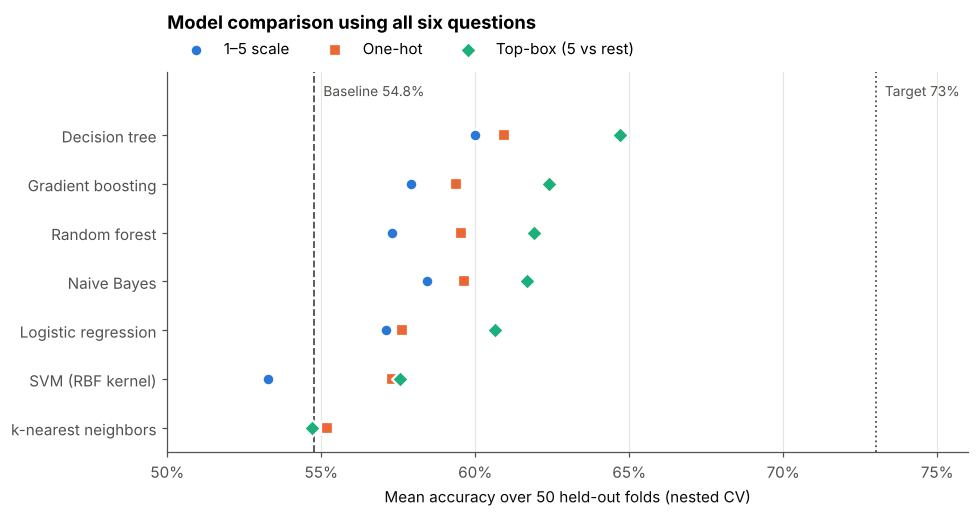

In [5]:
baseline_accuracy = means.loc["baseline", "ordinal"]
plot_means = means.loc[order].drop(index="baseline")
rows = np.arange(len(plot_means))

fig, ax = plt.subplots(figsize=(9, 4.8))
for encoding, (color, marker) in ENCODING_STYLES.items():
    ax.scatter(
        plot_means[encoding],
        rows,
        color=color,
        marker=marker,
        s=60,
        edgecolor="white",
        linewidth=1.5,
        label=ENCODING_NAMES[encoding],
        zorder=3,
    )
for value, text, style in [
    (baseline_accuracy, f"Baseline {baseline_accuracy:.1%}", "--"),
    (TARGET_ACCURACY, f"Target {TARGET_ACCURACY:.0%}", ":"),
]:
    ax.axvline(value, color=MUTED, linestyle=style, linewidth=1.2)
    ax.text(value + 0.003, -0.9, text, color=MUTED, fontsize=9, va="center")

ax.set_yticks(rows, [MODEL_NAMES[m] for m in plot_means.index])
ax.set_ylim(len(rows) - 0.5, -1.3)
ax.set_xlim(0.5, 0.76)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean accuracy over 50 held-out folds (nested CV)")
ax.set_title("Model comparison using all six questions", loc="left", pad=28)
ax.legend(ncols=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()

- **No model reaches 73% with all six questions.** Every configuration lands between 53% and
  65%. That's better than the 54.8% baseline, but far from the target.
- **Top-box encoding wins for 6 of 7 models.** What predicts happiness is whether the customer
  was *fully* satisfied (answered 5), not small differences between 3 and 4.
- **Flexibility doesn't pay.** The simplest model, a decision tree, scores highest. Naive Bayes
  and logistic regression are within about 2 points of random forest and gradient boosting.
  kNN and SVM barely beat the baseline. With 126 noisy rows, extra flexibility mostly fits
  noise.
- The spread across folds is large (±6–9 points). Section 3 checks which gaps are real.

## 3. Are the differences real?

The 50 fold scores of two models come from the same splits, and CV training sets overlap.
So a plain t-test is overconfident. We use the **corrected resampled t-test** (Nadeau & Bengio),
which widens the variance to account for that overlap. Here we compare the best configuration
with the best encoding of every other model.

In [6]:
best_config = accuracy.mean().idxmax()
print(f"Best: {MODEL_NAMES[best_config[0]]} with {ENCODING_NAMES[best_config[1]]} encoding")

rows = []
for model, encoding in means.idxmax(axis=1).items():
    if (model, encoding) == best_config:
        continue
    diff, p_value = corrected_ttest(accuracy[best_config], accuracy[(model, encoding)])
    rows.append(
        {
            "compared with": f"{MODEL_NAMES[model]} ({ENCODING_NAMES[encoding]})",
            "its accuracy": means.loc[model, encoding],
            "best is ahead by": diff,
            "p-value": p_value,
        }
    )
pd.DataFrame(rows).set_index("compared with").sort_values("its accuracy", ascending=False).round(3)

Best: Decision tree with Top-box (5 vs rest) encoding


,its accuracy,best is ahead by,p-value
compared with,,,
Gradient boosting (Top-box (5 vs rest)),0.624,0.023,0.246
Random forest (Top-box (5 vs rest)),0.619,0.028,0.247
Naive Bayes (Top-box (5 vs rest)),0.617,0.030,0.293
Logistic regression (Top-box (5 vs rest)),0.607,0.040,0.193
SVM (RBF kernel) (Top-box (5 vs rest)),0.576,0.071,0.066
k-nearest neighbors (One-hot),0.552,0.095,0.054
Baseline (always happy) (1–5 scale),0.548,0.099,0.017


- The best configuration **beats the baseline significantly** (p < 0.05). The model has found
  a real signal.
- It is **not significantly better than the other top models** (p > 0.05). On this data,
  several models are statistically tied.
- When models are tied, we prefer the **simplest and most explainable** one, which also happens
  to be the top scorer.

## 4. Beyond accuracy

Accuracy treats both mistakes equally. Two other views of the best encoding per model:

- **Balanced accuracy** is the average of the hit rates for happy and unhappy customers. Unlike
  accuracy, it can't be inflated by always predicting the majority class.
- **ROC AUC** asks how well the model *ranks* customers by their chance of being happy.

In [7]:
best_encoding_scores = {
    MODEL_NAMES[model]: scores[(model, encoding)]
    for model, encoding in means.idxmax(axis=1).items()
}
summary = summarize(best_encoding_scores)
summary[["accuracy_mean", "balanced_accuracy_mean", "roc_auc_mean", "f1_mean"]].round(3)

,accuracy_mean,balanced_accuracy_mean,roc_auc_mean,f1_mean
Decision tree,0.647,0.647,0.642,0.663
Gradient boosting,0.624,0.622,0.629,0.650
Random forest,0.619,0.616,0.651,0.650
Naive Bayes,0.617,0.612,0.618,0.655
Logistic regression,0.607,0.603,0.614,0.640
SVM (RBF kernel),0.576,0.568,0.612,0.620
k-nearest neighbors,0.552,0.532,0.595,0.642
Baseline (always happy),0.548,0.500,0.500,0.708


- The ranking by balanced accuracy matches the ranking by accuracy, so the winners are not
  just exploiting the 55/45 class split.
- Random forest ranks customers slightly better (ROC AUC 0.65 vs 0.64), but that gap is
  well within the fold-to-fold noise, and the tree classifies best.
- The baseline has a high F1 (0.71) despite learning nothing. F1 for the "happy" class rewards
  always saying "happy", which is why we don't use F1 to choose models here.

## 5. What the best model learned

We refit the winning procedure on all 126 customers (tuning included) and print its rules.

In [8]:
best_model, best_encoding = best_config
assert best_config == ("decision_tree", "top_box"), "The text below assumes the tree won"

search = tuned(candidates[best_model], best_encoding).fit(X, y)
print("Selected hyperparameters:", search.best_params_)
print(export_text(search.best_estimator_["model"], feature_names=[f"{f}_is_5" for f in FEATURES]))

Selected hyperparameters: {'model__max_depth': 1, 'model__min_samples_leaf': 1}
|--- X1_is_5 <= 0.50
|   |--- class: 0
|--- X1_is_5 >  0.50
|   |--- class: 1



Tuning picks a tree of **depth 1**, so the model is a single rule:

> **A customer is happy if their order was delivered fully on time (X1 = 5).**

In the inner cross-validation, deeper trees (which bring in more questions) scored lower than
this single split. That matches the EDA: X1 is the strongest signal, and the other questions
add more noise than information when all six are used at once.

How does this rule perform customer by customer? Below, every customer is predicted by a
model that never saw them (5-fold cross-validated predictions).

In [9]:
cv_predictions = cross_val_predict(
    tuned(candidates[best_model], best_encoding),
    X,
    y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
)
matrix = pd.DataFrame(
    confusion_matrix(y, cv_predictions),
    index=["actually unhappy", "actually happy"],
    columns=["predicted unhappy", "predicted happy"],
)
matrix["correctly classified"] = (np.diag(matrix) / matrix.sum(axis=1)).map("{:.0%}".format)
matrix

,predicted unhappy,predicted happy,correctly classified
actually unhappy,37,20,65%
actually happy,24,45,65%


The rule is equally good (or bad) on both classes, catching about two thirds of the unhappy
customers. Business reading: *a customer whose delivery was not fully on time is the one most
at risk of being unhappy.*

## 6. Why not report a single train/test split?

Most quick solutions use one random 80/20 split. To see how much that number depends on luck,
we evaluate the **same rule** (X1 = 5 → happy) on 500 different random splits. The rule barely
changes between splits, so almost all of the variation comes from which 26 customers happen
to land in the test set.

In [10]:
split_scores = []
for seed in range(500):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=seed
    )
    split_scores.append(clone(search.best_estimator_).fit(X_train, y_train).score(X_test, y_test))
split_scores = pd.Series(split_scores)

nested_mean = accuracy[best_config].mean()
share_at_target = (split_scores >= TARGET_ACCURACY).mean()
print(f"Single-split accuracy ranges from {split_scores.min():.1%} to {split_scores.max():.1%}")
print(f"{share_at_target:.0%} of splits reach the {TARGET_ACCURACY:.0%} target")

Single-split accuracy ranges from 38.5% to 84.6%
26% of splits reach the 73% target


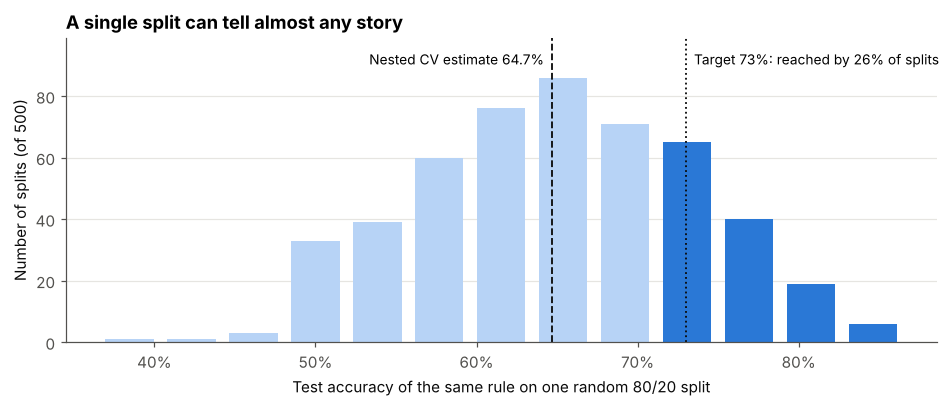

In [11]:
counts = split_scores.round(4).value_counts().sort_index()

colors = [BLUE if score >= TARGET_ACCURACY else LIGHT_BLUE for score in counts.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(counts.index, counts.values, width=0.03, color=colors)
label_y = counts.max() * 1.05
ax.axvline(nested_mean, color=INK, linestyle="--", linewidth=1.2)
ax.text(
    nested_mean - 0.005, label_y, f"Nested CV estimate {nested_mean:.1%}", ha="right", fontsize=9
)
ax.axvline(TARGET_ACCURACY, color=INK, linestyle=":", linewidth=1.2)
ax.text(
    TARGET_ACCURACY + 0.005,
    label_y,
    f"Target {TARGET_ACCURACY:.0%}: reached by {share_at_target:.0%} of splits",
    fontsize=9,
)
ax.set_ylim(0, counts.max() * 1.15)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Test accuracy of the same rule on one random 80/20 split")
ax.set_ylabel("Number of splits (of 500)")
ax.set_title("A single split can tell almost any story", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "single_split_spread.png", bbox_inches="tight")
plt.show()

The same one-line rule scores anywhere from 38% to 85% depending on the split, and
**about one split in four reaches the 73% target**. A report that shows one such split would
"meet" the goal, then disappoint on the private test set.

Nested CV gives the number to expect on new customers. It's lower, but it's honest, and it
comes with an uncertainty range.

## Summary

| | |
|---|---|
| Best procedure | decision tree on top-box answers → a single rule, **X1 = 5 → happy** |
| Expected accuracy on new customers | **≈ 65%** (nested CV, 50 folds), vs 54.8% baseline |
| Significantly better than baseline? | yes (corrected t-test, p < 0.05) |
| Significantly better than other top models? | no, they're statistically tied, so we prefer the simplest |

**Why this is a stronger answer than "73% on a test split":** the estimate is protected against
lucky splits and tuning leakage, it comes with a significance test, and the model is a rule a
manager can act on. A single-split 73% is reachable here, but by chance, as section 6 showed.